In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [14]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [16]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)


In [17]:
import warnings
warnings.filterwarnings("ignore")

In [18]:
sns.set_theme(style="whitegrid")
print("All libraries imported successfully!")

All libraries imported successfully!


In [19]:
values_df = pd.read_csv(r"C:\Users\KIIT\Downloads\PRCP-1016-HeartDieseasePred\Data\values.csv")
labels_df = pd.read_csv(r"C:\Users\KIIT\Downloads\PRCP-1016-HeartDieseasePred\Data\labels.csv")


In [20]:

print("Value table shape:", values_df.shape)
print("Label table shape:", labels_df.shape)

Value table shape: (180, 14)
Label table shape: (180, 2)


In [21]:
display(values_df.head())


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


In [22]:
display(labels_df.head())

,patient_id,heart_disease_present
0,0z64un,0
1,ryoo3j,0
2,yt1s1x,1
3,l2xjde,1
4,oyt4ek,0


In [23]:
print("Value columns:", values_df.columns.tolist())
print("Label columns:", labels_df.columns.tolist())

Value columns: ['patient_id', 'slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina']
Label columns: ['patient_id', 'heart_disease_present']


In [24]:
ID_COL = "patient_id"
TARGET_COL = "heart_disease_present"

if TARGET_COL not in labels_df.columns:
    raise ValueError(
        f"Target column '{TARGET_COL}' not found. "
        f"Available columns: {labels_df.columns.tolist()}"
    )

if ID_COL in values_df.columns and ID_COL in labels_df.columns:

    if values_df[ID_COL].duplicated().any():
        raise ValueError("Duplicate patient IDs in value table.")

    if labels_df[ID_COL].duplicated().any():
        raise ValueError("Duplicate patient IDs in label table.")

    data = pd.merge(
        values_df,
        labels_df[[ID_COL, TARGET_COL]],
        on=ID_COL,
        how="inner",
        validate="one_to_one"
    )

else:
    
    if len(values_df) != len(labels_df):
        raise ValueError(
            "The files have different row counts. "
            "Check the patient matching."
        )

    data = values_df.copy()
    data[TARGET_COL] = labels_df[TARGET_COL].to_numpy()

print("Combined dataset shape:", data.shape)



Combined dataset shape: (180, 15)


In [25]:
print("\nFirst five rows:")
display(data.head())



First five rows:


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [26]:
print("\nColumn names:")
print(data.columns.tolist())



Column names:
['patient_id', 'slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina', 'heart_disease_present']


In [27]:
print("\nTarget distribution:")
print(data[TARGET_COL].value_counts(dropna=False))


Target distribution:
heart_disease_present
0    100
1     80
Name: count, dtype: int64


In [28]:
data.shape

(180, 15)

In [29]:
data.info()
data.isnull().sum()
data.describe(include="all").T
data[TARGET_COL].value_counts(dropna=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

heart_disease_present
0    100
1     80
Name: count, dtype: int64

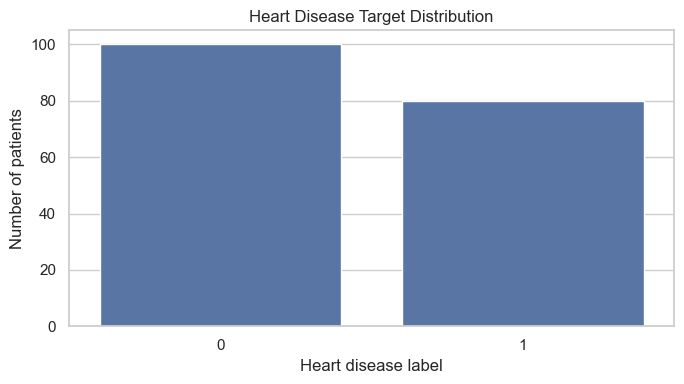

In [30]:
plt.figure(figsize=(7, 4))
sns.countplot(data=data, x=TARGET_COL)
plt.title("Heart Disease Target Distribution")
plt.xlabel("Heart disease label")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.show()

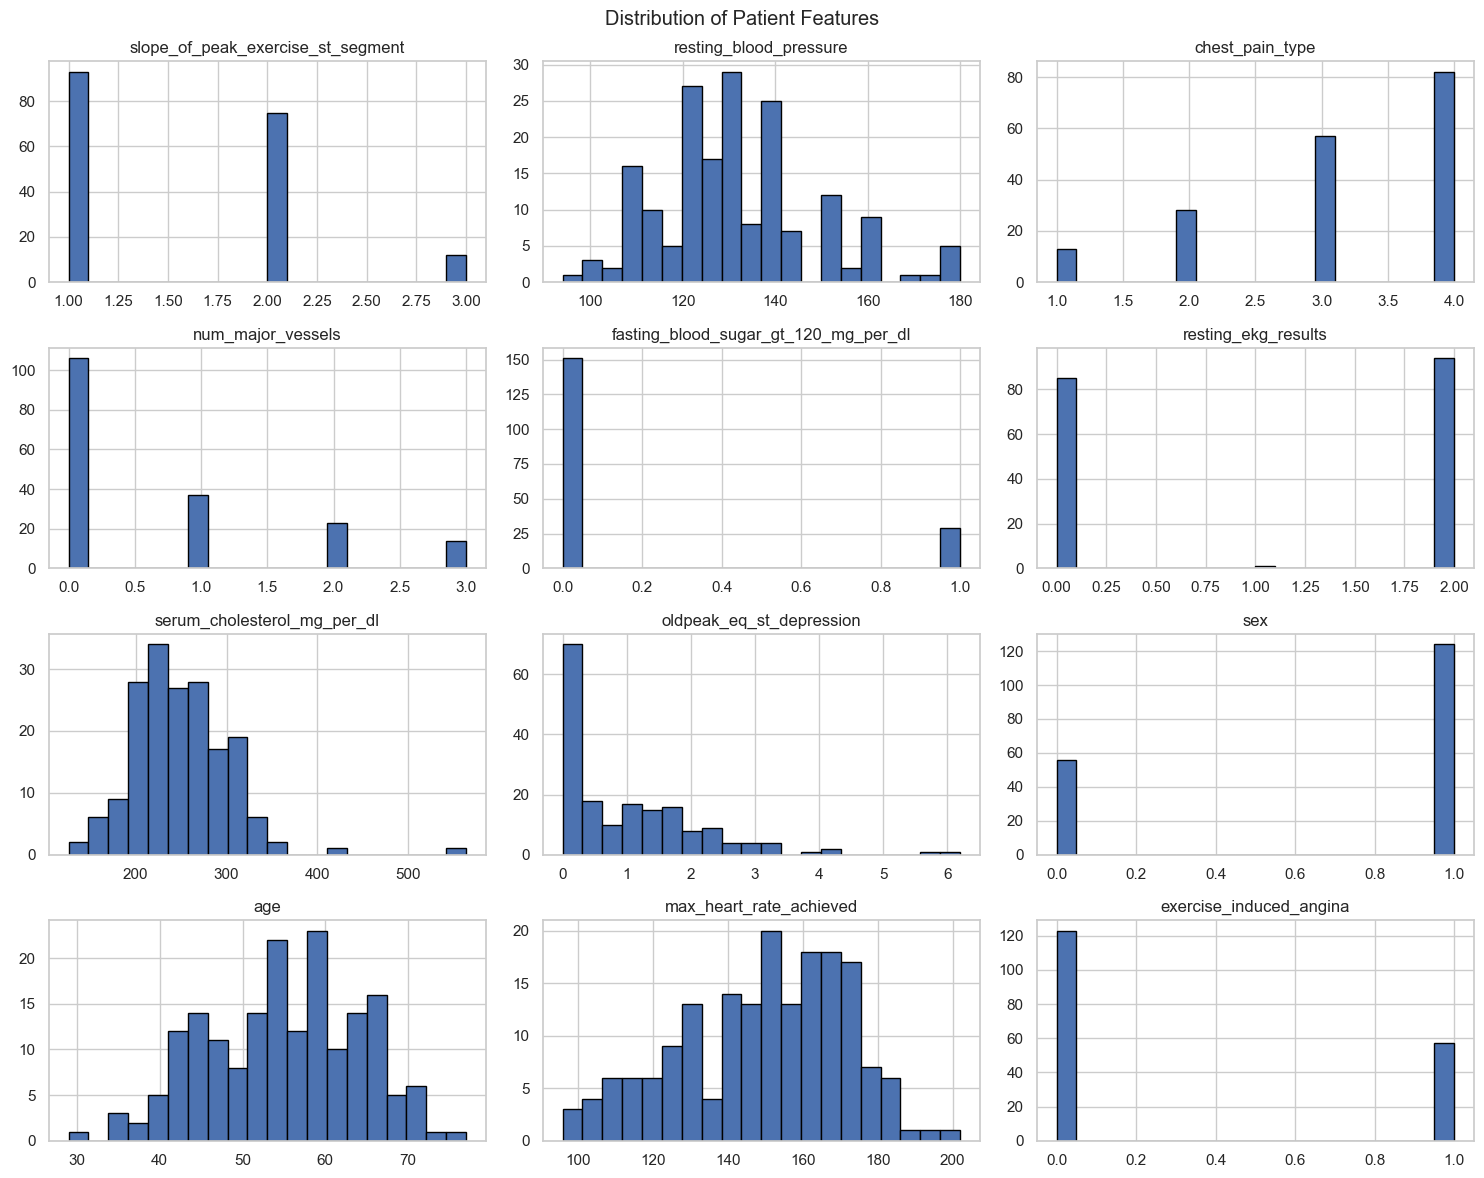

In [31]:
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()

numeric_features = [
    c for c in numeric_cols
    if c not in [TARGET_COL, ID_COL]
]

data[numeric_features].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Patient Features")
plt.tight_layout()
plt.show()

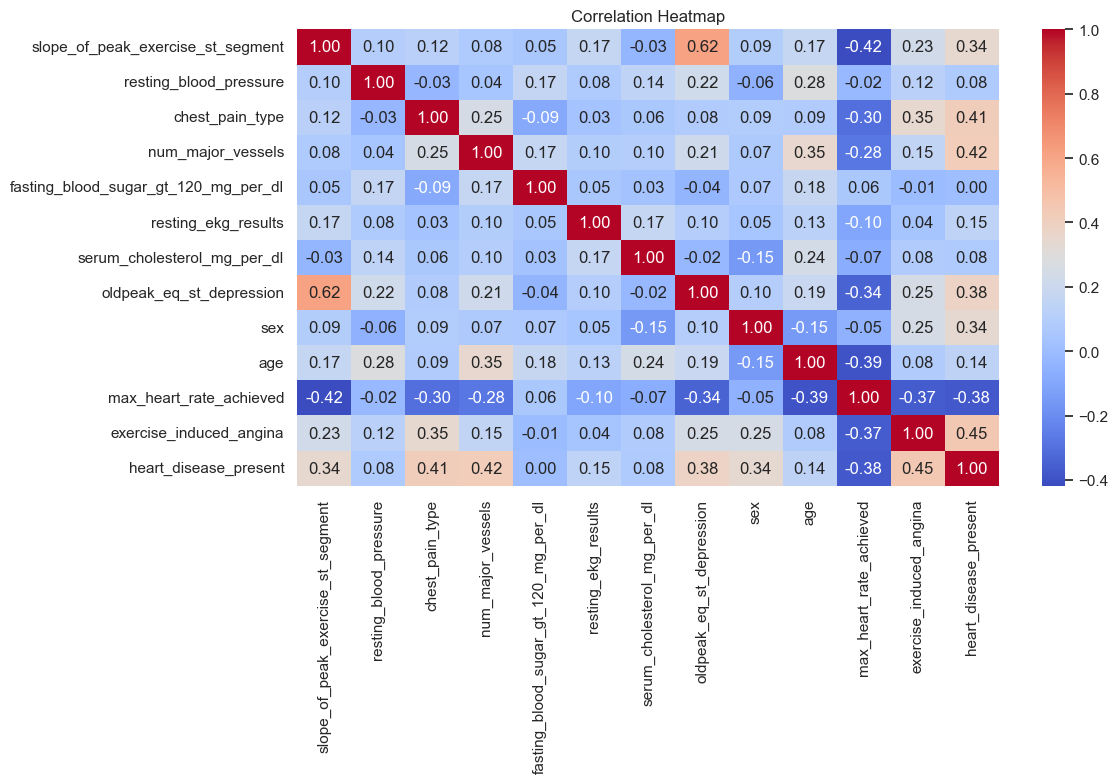

In [32]:
corr_data = data.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

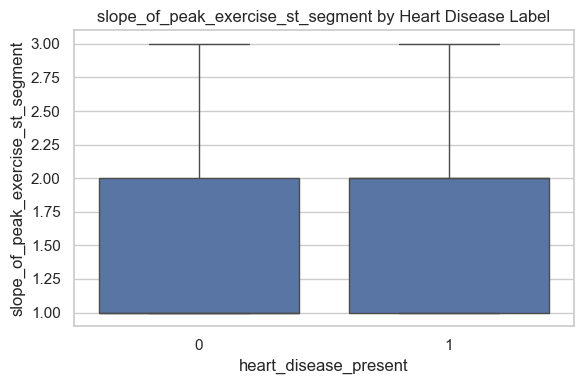

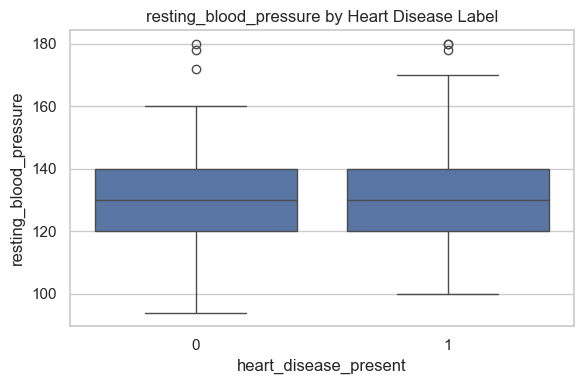

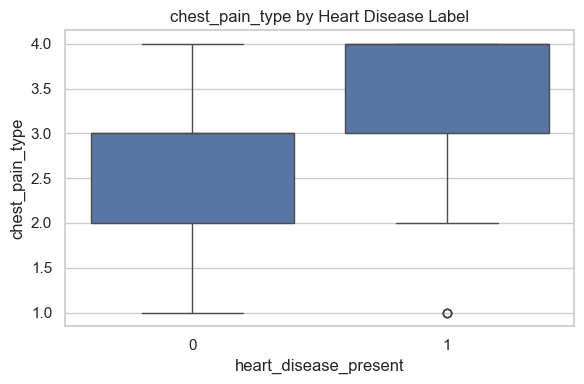

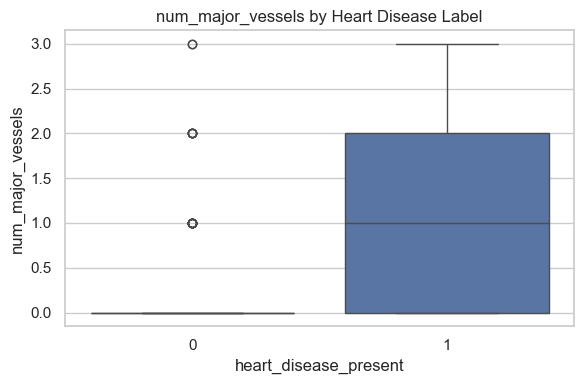

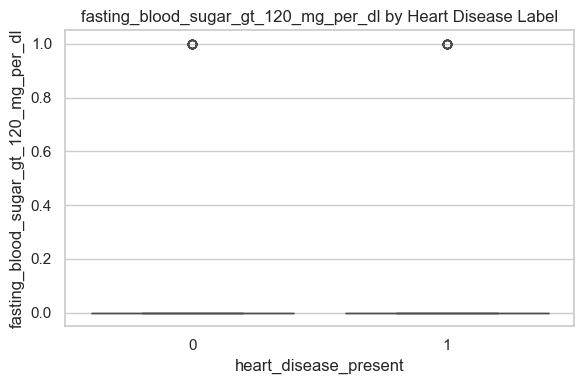

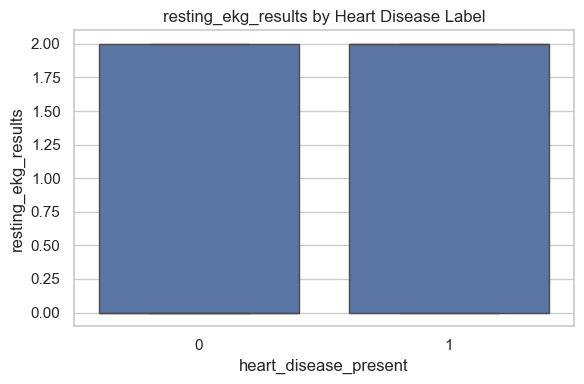

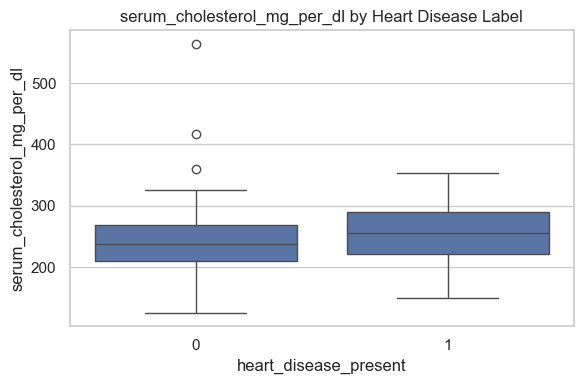

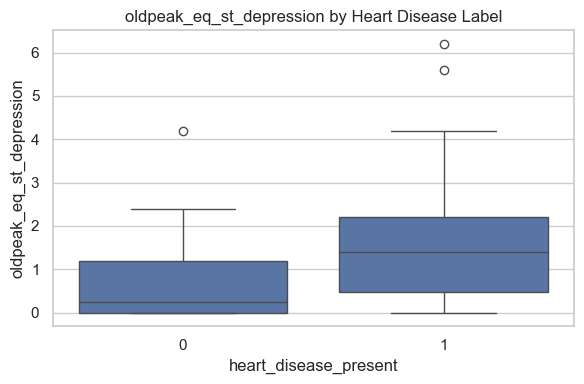

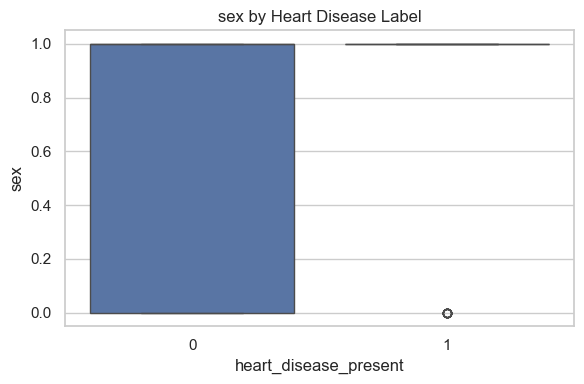

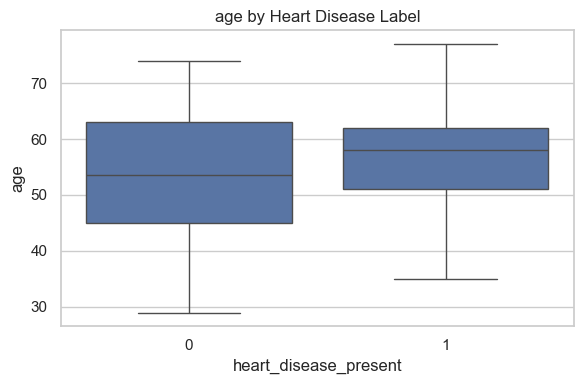

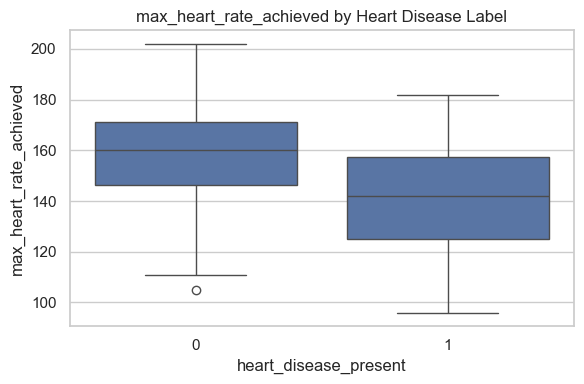

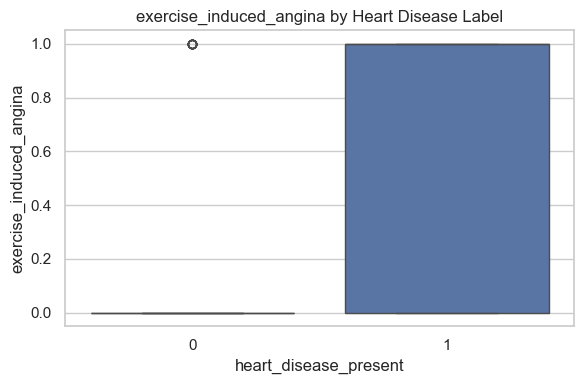

In [33]:
for col in numeric_features:
    plt.figure(figsize=(6, 4))

    sns.boxplot(data=data, x=TARGET_COL, y=col)

    plt.title(f"{col} by Heart Disease Label")
    plt.tight_layout()
    plt.show()

In [34]:
data = data.dropna(subset=[TARGET_COL]).copy()
X = data.drop(
    columns=[TARGET_COL, ID_COL],
    errors="ignore"
)

y = data[TARGET_COL]
X = X.dropna(axis=1, how="all")

valid_rows = ~X.isna().all(axis=1)
X = X.loc[valid_rows]
y = y.loc[valid_rows]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]


print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target classes:", y.value_counts().to_dict())

Numerical features: ['slope_of_peak_exercise_st_segment', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina']
Categorical features: ['thal']
Target classes: {0: 100, 1: 80}


In [35]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (144, 13)
Testing data: (36, 13)


In [37]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42,
        min_samples_leaf=3
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        min_samples_leaf=2
    ),

   

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

In [38]:
POSITIVE_LABEL = sorted(y.unique(), key=str)[-1]

if y.nunique() != 2:
    raise ValueError(
        "This evaluation code expects a binary target. "
        "Check your label definitions."
    )

if POSITIVE_LABEL not in y.unique():
    raise ValueError("POSITIVE_LABEL does not match a target class.")

results = []
trained_models = {}

for name, algorithm in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    model_classes = list(pipeline.named_steps["model"].classes_)
    positive_index = model_classes.index(POSITIVE_LABEL)
    y_probability = pipeline.predict_proba(X_test)[:, positive_index]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred,
        pos_label=POSITIVE_LABEL,
        zero_division=0
    )
    recall = recall_score(
        y_test, y_pred,
        pos_label=POSITIVE_LABEL,
        zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred,
        pos_label=POSITIVE_LABEL,
        zero_division=0
    )
    auc = roc_auc_score(
        (y_test == POSITIVE_LABEL).astype(int),
        y_probability
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[
            next(c for c in model_classes if c != POSITIVE_LABEL),
            POSITIVE_LABEL
        ]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall/Sensitivity": recall,
        "Specificity": specificity,
        "F1-score": f1,
        "ROC-AUC": auc
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Recall/Sensitivity",
    ascending=False
).reset_index(drop=True)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall/Sensitivity,Specificity,F1-score,ROC-AUC
0,Random Forest,0.889,0.800,1.000,0.80,0.889,0.959
1,Gradient Boosting,0.917,0.842,1.000,0.85,0.914,0.956
2,Logistic Regression,0.833,0.778,0.875,0.80,0.824,0.941
3,KNN,0.889,0.875,0.875,0.90,0.875,0.914
4,SVM,0.806,0.737,0.875,0.75,0.800,0.947
5,Decision Tree,0.806,0.765,0.812,0.80,0.788,0.819


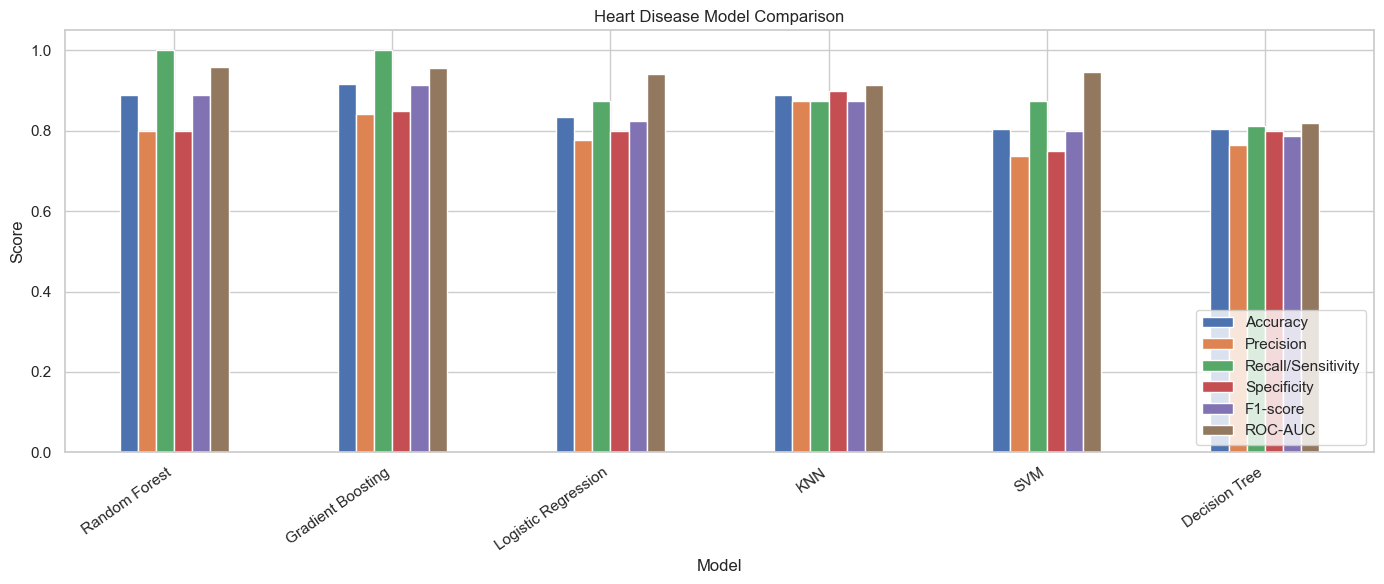

In [39]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall/Sensitivity",
    "Specificity",
    "F1-score",
    "ROC-AUC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Heart Disease Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Candidate model: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.80      0.89        20
           1       0.80      1.00      0.89        16

    accuracy                           0.89        36
   macro avg       0.90      0.90      0.89        36
weighted avg       0.91      0.89      0.89        36



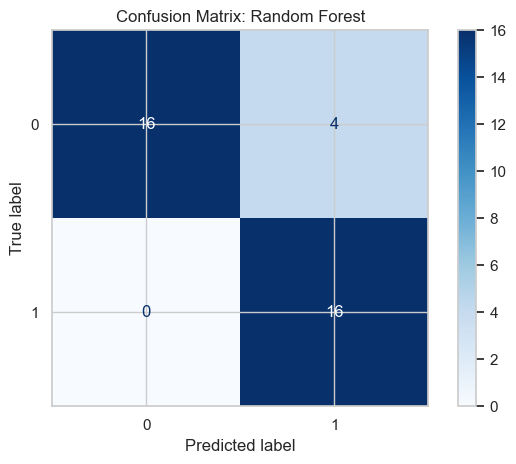

In [40]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Candidate model:", best_model_name)

y_pred_best = best_model.predict(X_test)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    labels=[
        next(c for c in best_model.named_steps["model"].classes_
             if c != POSITIVE_LABEL),
        POSITIVE_LABEL
    ],
    cmap="Blues"
)

plt.title(f"Confusion Matrix: {best_model_name}")
plt.tight_layout()
plt.show()

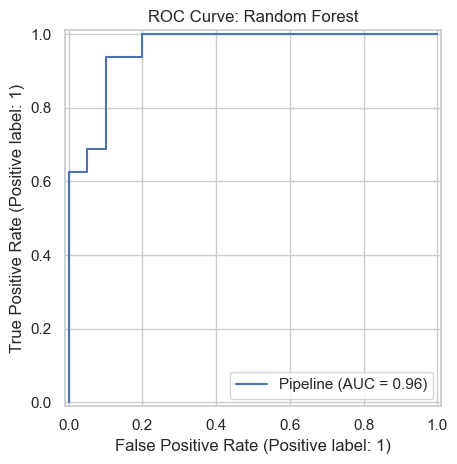

In [41]:
RocCurveDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    pos_label=POSITIVE_LABEL
)

plt.title(f"ROC Curve: {best_model_name}")
plt.tight_layout()
plt.show()

In [74]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, algorithm in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV F1": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values(
    "Mean CV F1",
    ascending=False
)

display(cv_df.round(3))

,Model,Mean CV F1,Standard Deviation
4,SVM,0.784,0.041
2,Random Forest,0.776,0.078
0,Logistic Regression,0.772,0.052
5,Gradient Boosting,0.769,0.067
1,Decision Tree,0.743,0.074
3,KNN,0.726,0.075


,Feature,Importance
13,cat__thal_normal,0.113647
2,num__chest_pain_type,0.109474
10,num__max_heart_rate_achieved,0.104232
14,cat__thal_reversible_defect,0.094945
7,num__oldpeak_eq_st_depression,0.093389
9,num__age,0.091874
3,num__num_major_vessels,0.080485
6,num__serum_cholesterol_mg_per_dl,0.079182
11,num__exercise_induced_angina,0.059945
1,num__resting_blood_pressure,0.056851


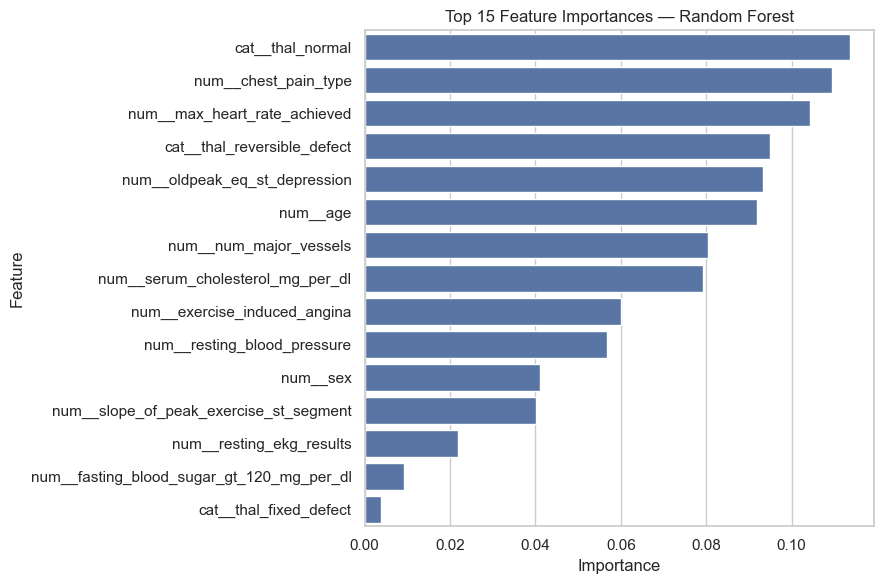

In [76]:
tree_model_name = "Random Forest"
tree_pipeline = trained_models[tree_model_name]

feature_names = (
    tree_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_values = (
    tree_pipeline
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15))

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances — Random Forest")
plt.tight_layout()
plt.show()

In [78]:
joblib.dump(
    {
        "model": best_model,
        "model_name": best_model_name,
        "feature_columns": X.columns.tolist(),
        "target_column": TARGET_COL,
        "positive_label": POSITIVE_LABEL
    },
    "heart_disease_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [80]:
saved_model = joblib.load("heart_disease_model.joblib")

loaded_pipeline = saved_model["model"]

print("Loaded model:", saved_model["model_name"])

Loaded model: Random Forest


In [86]:
new_patient = pd.DataFrame([{
}])

if list(new_patient.columns) != X.columns.tolist():
    print("Add all required feature columns in the correct order.")
else:
    prediction = loaded_pipeline.predict(new_patient)[0]

    print("Predicted class:", prediction)

    probabilities = loaded_pipeline.predict_proba(new_patient)[0]

    print("Class probabilities:")
    print(dict(zip(
        loaded_pipeline.named_steps["model"].classes_,
        probabilities
    )))

Add all required feature columns in the correct order.


In [88]:
results_df.to_csv(
    "heart_disease_model_comparison.csv",
    index=False
)

cv_df.to_csv(
    "heart_disease_cross_validation.csv",
    index=False
)

print("Model comparison reports exported!")

Model comparison reports exported!


# Hospital recommendations :-

1. Early assessment: Use a validated prediction system only to support clinicians in identifying patients who may need further assessment.                                                                                                                                                                                                                                                   
2. Patient monitoring: Establish clear follow-up processes for patients identified as potentially high risk.                                                                                                                                                                                                                                                                                                                                
3. Health education: Support clinician-led advice on physical activity, diet, smoking cessation, blood pressure, diabetes, and cholesterol management.                                                                                                                                                                                                                                                                      
4. Data quality: Standardize patient measurements, units, coding, and missing-value documentation.                                                                                                                                                                                                                                                                                                                                    
5. Model monitoring: Track false negatives, false positives, sensitivity, specificity, and performance changes over time.                                                                                                                                                                                                                                                                                                                        
6. Fairness and privacy: Evaluate performance across clinically relevant patient groups and protect confidential medical data.                                                                                                                                                                                                                                                                                                                                       
7. Clinical approval: Test the model on independent hospital data and conduct an appropriate prospective evaluation before considering deployment.                                                                                                                                                                                                                                                                                                                      
A prediction must never delay emergency treatment or replace a clinician's assessment.

# Challenges Faced and Solutions :-

| Challenge | Technique Used | Reason |
|---|---|---|
| Two separate datasets | Merge by patient ID | Correctly match features with labels |
| Missing data | Median and mode imputation | Retain usable patient records |
| Categorical features | One-hot encoding | Convert categories into usable model inputs |
| Different numerical scales | StandardScaler | Improve scale-sensitive model training |
| Class imbalance | Stratified split and class-aware metrics | Evaluate minority-class performance more carefully |
| Overfitting risk | Train/test split and cross-validation | Assess performance beyond a single training fit |
| Model selection | Compare six algorithms | Identify a suitable candidate based on measured results |
| False negatives | Recall and confusion matrix | Identify positive cases the model misses |
| Limited generalization | Recommend external validation | Check performance on patients outside the supplied dataset |

# Conclusion — Heart Disease Prediction

The PRCP-1016 Heart Disease Prediction project applies data science and machine learning techniques to analyze patient data and classify heart disease outcomes.

The project includes data loading, data cleaning, exploratory data analysis, preprocessing, training multiple classification algorithms, and comparing their performance using accuracy, precision, recall, specificity, F1-score.

Cross-validation and confusion-matrix analysis help assess the reliability and limitations of the candidate models. The best candidate is selected using the measured results, with particular attention to sensitivity and false-negative cases.

The analysis can help identify patterns in the supplied dataset and inform recommendations for further clinical assessment and patient monitoring. However, the model is an educational prototype, not a clinically approved diagnostic tool. Independent validation, fairness assessment, probability calibration, privacy safeguards, and appropriate clinical approval are necessary before any real-world deployment.